# Uplift Model and Targeting: AI Learning Assistant Campaign (LearnLoop, synthetic data)

**Question:** Who responds *because of* the campaign, and can targeting beat messaging everyone?

**Design:** Two-model (T-learner) uplift estimate for each variant vs control, using gradient boosting on platform, country, user type, age group, acquisition channel and prior sessions. 5-fold cross-fitting scores every user out-of-sample, and because assignment was randomised, uplift is measured directly in any group as treated rate minus control rate.

**Headline result:** The model did not reliably rank users: measured uplift was flat and noisy across predicted-uplift quintiles, and gain curves stayed near random targeting. A simple rule (Variant C for Android users in India, 22% of users) captured 33% of incremental conversions vs 17% for the model's top 22%.

**Interpretation:** Use simple, explainable segment targeting and confirm it in a follow-up experiment.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

## 1. Load data
Load the 28,266-user analysis table. Net conversion = converted and not refunded.

In [19]:
SEED = 42
d = pd.read_csv("/content/drive/MyDrive/analysis_users.csv")
print(d.head(5))
d["refunded_14d"] = d["refunded_14d"].fillna(0)
d["net_converted"] = (d["converted_14d"] - d["refunded_14d"]).clip(lower=0)

   user_id    variant        assignment_ts platform  country user_type age_group acquisition_channel  prior_sessions_30_d  converted_14d  refunded_14d  unsub_14d
0  U000001  variant_b  2026-08-09 07:32:00  Android    India  existing     35-44         paid_social                    8              0             0          0
1  U000002  variant_b  2026-08-03 18:16:00      iOS   Brazil  existing       55+             organic                    8              0             0          0
2  U000007  variant_b  2026-08-02 08:23:00      iOS    India  existing     25-34              search                   14              0             0          0
3  U000008  variant_b  2026-08-09 10:43:00  Android    India  existing     35-44            referral                   13              0             0          0
4  U000010    control  2026-08-11 01:42:00  Android  Germany  existing     35-44             organic                   12              0             0          0


## 2. Features
Five categorical features plus prior sessions; missing categories are set to "unknown".

In [5]:
CAT = ["platform", "country", "user_type", "age_group", "acquisition_channel"]
NUM = ["prior_sessions_30_d"]
FEATURES = CAT + NUM
d[CAT] = d[CAT].fillna("unknown")

## 3. Sanity check
Conversion by arm matches notebook 01: 4.84% (control), 6.96% (B), 7.52% (C). Net of refunds: 4.63%, 6.73%, 6.81%.

In [6]:
print(d.shape)
print(d.groupby("variant")[["converted_14d", "net_converted"]].mean().round(4))

(28266, 13)
           converted_14d  net_converted
variant                                
control           0.0484         0.0463
variant_b         0.0696         0.0673
variant_c         0.0752         0.0681


## 4. Model
One-hot encoding plus shallow gradient boosting (depth 2) to limit overfitting at about 9,000 users per arm.

In [7]:
def make_model():
    pre = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)],
        remainder="passthrough",
    )
    gbm = GradientBoostingClassifier(
        n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED
    )
    return Pipeline([("pre", pre), ("gbm", gbm)])

## 5. Cross-fitted uplift (T-learner)
One model on treated users, one on control; uplift = difference in predicted conversion. 5-fold cross-fitting means no user is scored by a model that saw them.

In [8]:
def crossfit_uplift(df, arm, outcome, n_splits=5):
    sub = df[df.variant.isin(["control", arm])].reset_index(drop=True)
    sub["treated"] = (sub.variant == arm).astype(int)
    strat = sub["treated"].astype(str) + "_" + sub[outcome].astype(str)
    score = np.zeros(len(sub))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    for tr, te in skf.split(sub, strat):
        train, test = sub.iloc[tr], sub.iloc[te]
        t, c = train[train.treated == 1], train[train.treated == 0]
        m_t = make_model().fit(t[FEATURES], t[outcome])
        m_c = make_model().fit(c[FEATURES], c[outcome])
        score[te] = m_t.predict_proba(test[FEATURES])[:, 1] - m_c.predict_proba(test[FEATURES])[:, 1]
    sub["uplift_score"] = score
    return sub

## 6. Measured uplift
Assignment was random, so uplift in any group is its treated conversion rate minus its control rate.

In [9]:
def uplift_rate(g, outcome):
    # measured uplift in a group: treated conversion rate minus control conversion rate
    return g.loc[g.treated == 1, outcome].mean() - g.loc[g.treated == 0, outcome].mean()

## 7. Quintile table
Users are ranked by predicted uplift into 5 groups; measured uplift is compared across groups.

In [10]:
def quantile_table(sub, outcome, q=5):
    sub = sub.copy()
    sub["bin"] = pd.qcut(sub.uplift_score.rank(method="first", ascending=False), q, labels=range(1, q + 1))
    rows = []
    for b, g in sub.groupby("bin", observed=True):
        rows.append(dict(
            quintile=int(b), users=len(g),
            treated=int((g.treated == 1).sum()), control=int((g.treated == 0).sum()),
            treated_rate=g.loc[g.treated == 1, outcome].mean(),
            control_rate=g.loc[g.treated == 0, outcome].mean(),
            measured_uplift_pp=uplift_rate(g, outcome) * 100,
            avg_predicted_uplift_pp=g.uplift_score.mean() * 100,
        ))
    return pd.DataFrame(rows)

## 8. Gain curve
Incremental conversions captured as more users are messaged, highest predicted uplift first.

In [11]:
def gain_curve(sub, outcome):
    s = sub.sort_values("uplift_score", ascending=False).reset_index(drop=True)
    n = len(s)
    cum_t = (s.treated * s[outcome]).cumsum().values
    cum_nt = s.treated.cumsum().values
    cum_c = ((1 - s.treated) * s[outcome]).cumsum().values
    cum_nc = (1 - s.treated).cumsum().values
    with np.errstate(divide="ignore", invalid="ignore"):
        qini = cum_t - cum_c * cum_nt / np.where(cum_nc == 0, np.nan, cum_nc)
    qini = np.nan_to_num(qini)
    frac = np.arange(1, n + 1) / n
    return frac, qini

## 9. Targeting policy
Share of total benefit kept if only the top X% by predicted uplift are messaged. Random targeting keeps X%.

In [12]:
def policy_table(sub, outcome, fractions=(0.2, 0.4, 0.6, 0.8, 1.0)):
    s = sub.sort_values("uplift_score", ascending=False).reset_index(drop=True)
    n = len(s)
    total = uplift_rate(s, outcome) * n
    rows = []
    for f in fractions:
        g = s.iloc[: int(f * n)]
        r = uplift_rate(g, outcome)
        rows.append(dict(
            target_top_pct=int(f * 100), users=len(g),
            measured_uplift_pp=r * 100,
            extra_conversions_per_1000_messaged=r * 1000,
            share_of_total_benefit=r * len(g) / total,
            random_targeting_share=f,
        ))
    return pd.DataFrame(rows)

## 10. Fit the models
Four runs: Variants B and C, each for conversion and conversion net of refunds.

In [13]:
ARMS = ["variant_b", "variant_c"]
OUTCOMES = {"converted_14d": "Premium conversion", "net_converted": "Conversion net of refunds"}

results = {}
for outcome in OUTCOMES:
    for arm in ARMS:
        results[(outcome, arm)] = crossfit_uplift(d, arm, outcome)

print("fitted:", [f"{a} / {o}" for (o, a) in results])

fitted: ['variant_b / converted_14d', 'variant_c / converted_14d', 'variant_b / net_converted', 'variant_c / net_converted']


## 11. Results: quintiles
Measured uplift does not fall from quintile 1 to 5 (B: 2.5, 3.3, 0.2, 1.3, 3.3 pp; C: 2.2, 3.0, 3.6, 2.4, 2.2 pp), so the model's ranking is unreliable.

In [14]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

for (outcome, arm), sub in results.items():
    print(f"\n=== {arm} | {OUTCOMES[outcome]} | overall measured uplift: {uplift_rate(sub, outcome) * 100:.2f} pp ===")
    print(quantile_table(sub, outcome).round(4).to_string(index=False))


=== variant_b | Premium conversion | overall measured uplift: 2.12 pp ===
 quintile  users  treated  control  treated_rate  control_rate  measured_uplift_pp  avg_predicted_uplift_pp
        1   3801     1885     1916        0.0817        0.0564              2.5330                   5.3745
        2   3801     1859     1942        0.0764        0.0433              3.3131                   2.8802
        3   3801     1908     1893        0.0540        0.0523              0.1685                   1.8564
        4   3801     1789     2012        0.0671        0.0542              1.2902                   1.0397
        5   3801     1882     1919        0.0691        0.0360              3.3119                  -0.5651

=== variant_c | Premium conversion | overall measured uplift: 2.67 pp ===
 quintile  users  treated  control  treated_rate  control_rate  measured_uplift_pp  avg_predicted_uplift_pp
        1   3789     1843     1946        0.0760        0.0540              2.2006            

## 12. Results: targeting policy
No consistent gain over random targeting. B is above random at 20-40% reach and below at 60-80%; C stays close to random throughout.

In [15]:
for (outcome, arm), sub in results.items():
    print(f"\n=== {arm} | {OUTCOMES[outcome]} ===")
    print(policy_table(sub, outcome).round(4).to_string(index=False))


=== variant_b | Premium conversion ===
 target_top_pct  users  measured_uplift_pp  extra_conversions_per_1000_messaged  share_of_total_benefit  random_targeting_share
             20   3801              2.5257                              25.2574                  0.2386                     0.2
             40   7602              2.9293                              29.2931                  0.5534                     0.4
             60  11403              1.9973                              19.9733                  0.5660                     0.6
             80  15204              1.8238                              18.2382                  0.6891                     0.8
            100  19005              2.1172                              21.1724                  1.0000                     1.0

=== variant_c | Premium conversion ===
 target_top_pct  users  measured_uplift_pp  extra_conversions_per_1000_messaged  share_of_total_benefit  random_targeting_share
             20   3788  

## 13. Model vs a simple rule
For Variant C, messaging only Android users in India (22% of users) gives +4.0 pp uplift and captures 33% of the benefit, vs 17% for the model's top 22% (35% vs 24% net of refunds).

In [16]:
rows = []
for outcome in OUTCOMES:
    sub = results[(outcome, "variant_c")]
    total = uplift_rate(sub, outcome) * len(sub)
    rule = (sub.platform.str.lower() == "android") & (sub.country.str.lower() == "india")
    g_rule = sub[rule]
    top = sub.sort_values("uplift_score", ascending=False).iloc[: len(g_rule)]
    rows.append(dict(
        outcome=OUTCOMES[outcome],
        users_messaged=len(g_rule),
        pct_of_users=round(100 * len(g_rule) / len(sub), 1),
        rule_uplift_pp=round(uplift_rate(g_rule, outcome) * 100, 2),
        rule_share_of_benefit=round(uplift_rate(g_rule, outcome) * len(g_rule) / total, 3),
        model_uplift_pp=round(uplift_rate(top, outcome) * 100, 2),
        model_share_of_benefit=round(uplift_rate(top, outcome) * len(top) / total, 3),
    ))
print(pd.DataFrame(rows).to_string(index=False))

                  outcome  users_messaged  pct_of_users  rule_uplift_pp  rule_share_of_benefit  model_uplift_pp  model_share_of_benefit
       Premium conversion            4185          22.1            4.01                  0.331             2.06                   0.170
Conversion net of refunds            4185          22.1            3.43                  0.346             2.39                   0.242


## 14. Chart: uplift by quintile
Bars are not ordered from highest to lowest, which confirms the ranking is unreliable.

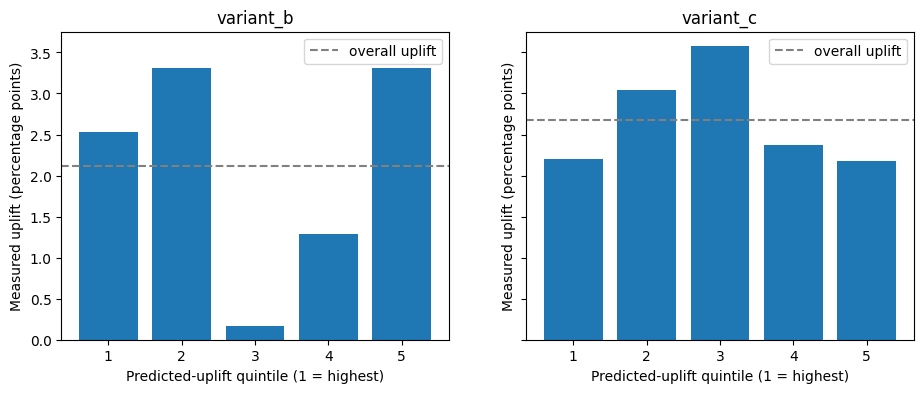

In [17]:
# 1) Measured uplift by predicted-uplift quintile
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, arm in zip(axes, ARMS):
    sub = results[("converted_14d", arm)]
    qt = quantile_table(sub, "converted_14d")
    ax.bar(qt.quintile.astype(str), qt.measured_uplift_pp)
    ax.axhline(uplift_rate(sub, "converted_14d") * 100, color="grey", ls="--", label="overall uplift")
    ax.set_title(arm)
    ax.set_xlabel("Predicted-uplift quintile (1 = highest)")
    ax.set_ylabel("Measured uplift (percentage points)")
    ax.legend()

## 15. Chart: cumulative gain
Both curves stay close to the random-targeting line, so the model adds little over random targeting.

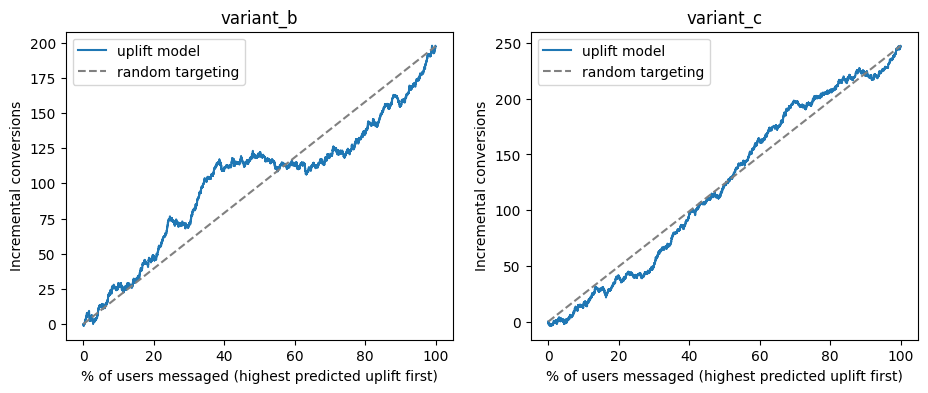

In [18]:
# 2) Cumulative gain vs random targeting
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, arm in zip(axes, ARMS):
    sub = results[("converted_14d", arm)]
    frac, qini = gain_curve(sub, "converted_14d")
    ax.plot(frac * 100, qini, label="uplift model")
    ax.plot([0, 100], [0, qini[-1]], ls="--", color="grey", label="random targeting")
    ax.set_title(arm)
    ax.set_xlabel("% of users messaged (highest predicted uplift first)")
    ax.set_ylabel("Incremental conversions")
    ax.legend()